# 🚁 UAV Aerial Mosaicking — Classical Baseline (SIFT & ORB)

Thực nghiệm ghép ảnh 2D từ video UAV bằng 2 thuật toán đặc trưng cổ điển (**SIFT** và **ORB**):
1. **DataLoader:** Đọc sequence ảnh keyframe và metadata (`config.cfg`, `trajectory.txt`).
2. **Feature Matching:** So sánh trực diện SIFT (float, L2-norm) và ORB (nhị phân, Hamming distance).
3. **Homography & RANSAC:** Ước lượng $H_{i \to i-1}$, lọc inliers, tính sai số reprojection RMSE.
4. **Global Canvas & Stitching:** Chiếu các frame lên hệ toạ độ toàn cảnh và ghép ảnh.
5. **Thực nghiệm song song:** Chạy cả **SIFT** và **ORB** trên cùng tập frame, xuất ảnh mosaic và log riêng biệt.

In [1]:
import os
import sys
import time
import json
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV Version: {cv2.__version__}")
print(f"NumPy Version:  {np.__version__}")


OpenCV Version: 5.0.0
NumPy Version:  2.4.6


In [2]:
# Đường dẫn dữ liệu và output
REPO_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = REPO_ROOT / "data"

# Chọn sequence thử nghiệm (mặc định phantom3-village-kfs)
SEQUENCE_NAME = "phantom3-village-kfs"
SEQUENCE_PATH = DATA_DIR / SEQUENCE_NAME

OUTPUT_DIR = REPO_ROOT / "notebooks" / "outputs" / "01_classical_baseline" / SEQUENCE_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Sequence Path: {SEQUENCE_PATH.resolve()}")
print(f"Output Path:   {OUTPUT_DIR.resolve()}")


Sequence Path: D:\fptu\_hoc-lieu\ky4\cvprj\data\phantom3-village-kfs
Output Path:   D:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\01_classical_baseline\phantom3-village-kfs


In [3]:
def load_sequence(seq_path: Path):
    """Đọc danh sách ảnh keyframe và metadata (xử lý cả thư mục lồng nhau)."""
    actual_dir = seq_path
    if (seq_path / seq_path.name).is_dir() and (seq_path / seq_path.name / "rgb").is_dir():
        actual_dir = seq_path / seq_path.name

    rgb_dir = actual_dir / "rgb"
    if not rgb_dir.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục rgb trong {actual_dir}")

    # Sắp xếp ảnh theo timestamp
    img_files = sorted(
        list(rgb_dir.glob("*.jpg")) + list(rgb_dir.glob("*.png")),
        key=lambda p: float(p.stem) if p.stem.replace(".", "", 1).isdigit() else p.name
    )

    # Đọc trajectory ground truth
    traj_file = actual_dir / "trajectory.txt"
    trajectories = {}
    if traj_file.exists():
        with open(traj_file, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 8:
                    trajectories[float(parts[0])] = [float(x) for x in parts[1:]]

    # Đọc config camera
    cfg_file = actual_dir / "config.cfg"
    camera_cfg = {}
    if cfg_file.exists():
        with open(cfg_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    camera_cfg[k.strip()] = v.strip()

    return img_files, trajectories, camera_cfg

img_files, trajectories, camera_cfg = load_sequence(SEQUENCE_PATH)
print(f"Tìm thấy: {len(img_files)} frames | {len(trajectories)} pose ground truth | {len(camera_cfg)} config keys")
if img_files:
    sample = cv2.imread(str(img_files[0]))
    print(f"Frame size: {sample.shape[1]}x{sample.shape[0]} px")


Tìm thấy: 406 frames | 406 pose ground truth | 5 config keys
Frame size: 1920x1080 px


### 2. Feature Extraction & Matching (SIFT vs ORB)
So sánh trực quan kết quả trích xuất và đối sánh giữa **SIFT** và **ORB** trên 2 frame đầu tiên.


SIFT:  856 matches (217.6 ms)
ORB :  731 matches (223.5 ms)


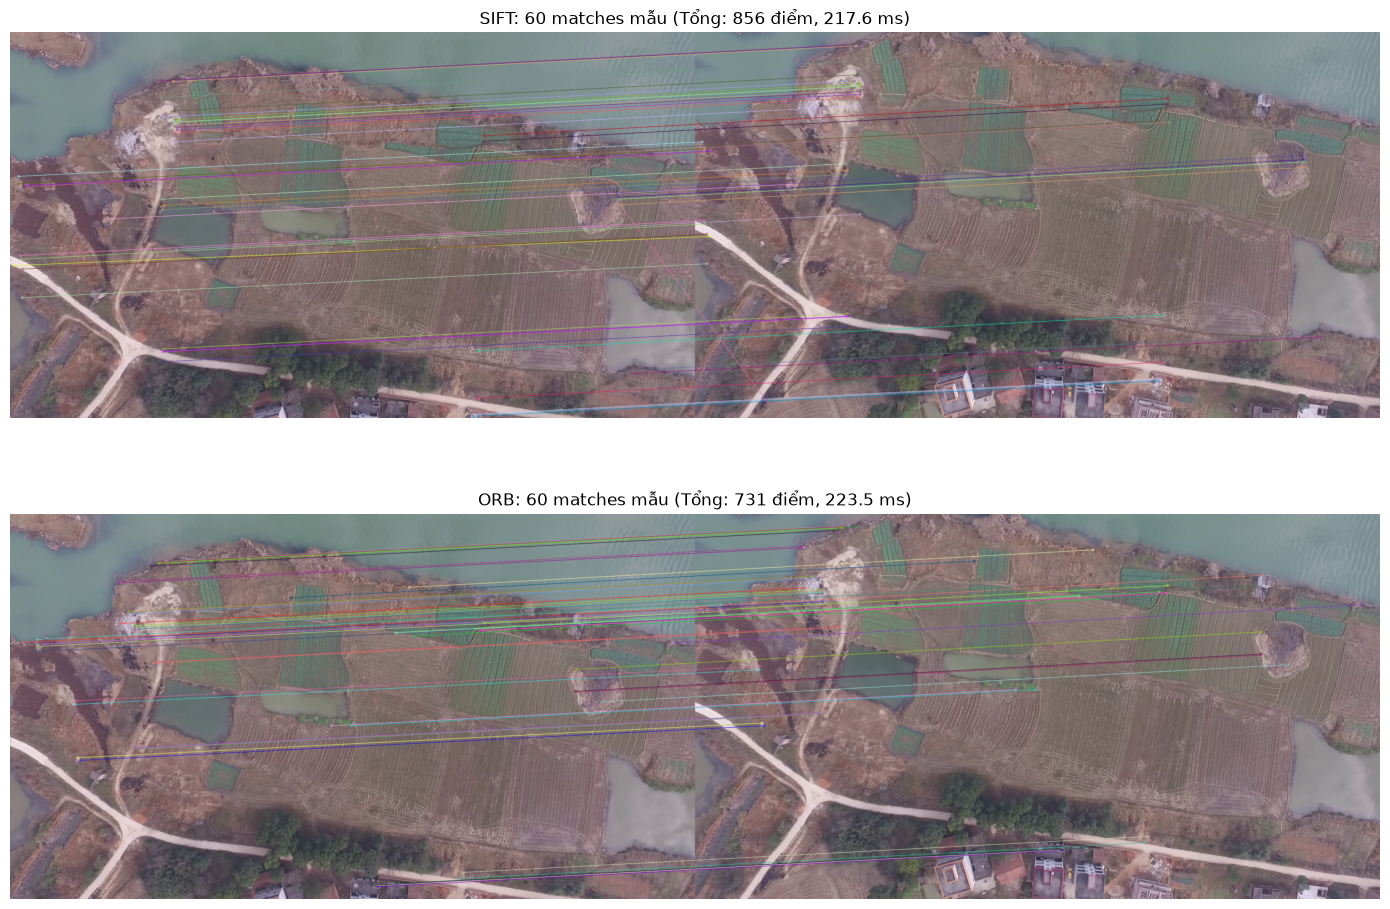

In [4]:
def extract_and_match(img1, img2, method="SIFT", max_features=2000, ratio_thresh=0.75):
    """Trích xuất keypoints và match giữa 2 ảnh bằng SIFT hoặc ORB."""
    g1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY) if len(img1.shape) == 3 else img1
    g2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY) if len(img2.shape) == 3 else img2

    t0 = time.perf_counter()
    if method.upper() == "SIFT":
        detector = cv2.SIFT_create(nfeatures=max_features)
        kp1, des1 = detector.detectAndCompute(g1, None)
        kp2, des2 = detector.detectAndCompute(g2, None)
        matcher = cv2.BFMatcher(cv2.NORM_L2)
    elif method.upper() == "ORB":
        detector = cv2.ORB_create(nfeatures=max_features)
        kp1, des1 = detector.detectAndCompute(g1, None)
        kp2, des2 = detector.detectAndCompute(g2, None)
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    else:
        raise ValueError(f"Unknown method: {method}")

    if des1 is None or des2 is None or len(des1) < 4 or len(des2) < 4:
        return [], kp1, kp2, 0.0

    matches = matcher.knnMatch(des1, des2, k=2)
    good = [m[0] for m in matches if len(m) == 2 and m[0].distance < ratio_thresh * m[1].distance]
    dur = time.perf_counter() - t0
    return good, kp1, kp2, dur

# Đối chiếu trực quan cả 2 thuật toán trên 2 frame đầu
if len(img_files) >= 2:
    im0 = cv2.imread(str(img_files[0]))
    im1 = cv2.imread(str(img_files[1]))
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    for idx, m_name in enumerate(["SIFT", "ORB"]):
        m_matches, kp_a, kp_b, m_dur = extract_and_match(im0, im1, method=m_name)
        print(f"{m_name:4s}: {len(m_matches):4d} matches ({m_dur*1000:.1f} ms)")
        vis = cv2.drawMatches(im0, kp_a, im1, kp_b, m_matches[:60], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        axes[idx].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        axes[idx].set_title(f"{m_name}: 60 matches mẫu (Tổng: {len(m_matches)} điểm, {m_dur*1000:.1f} ms)")
        axes[idx].axis("off")
    plt.tight_layout()
    plt.show()


### 3. Ước lượng Homography & RANSAC
Tìm ma trận biến đổi phối cảnh $H_{i \to i-1}$, lọc inliers, tính tỷ lệ inliers và reprojection RMSE.


In [5]:
def estimate_homography(kp_prev, kp_curr, matches, ransac_thresh=3.0):
    """Ước lượng H từ frame curr sang frame prev bằng RANSAC."""
    if len(matches) < 4:
        return None, np.array([]), 0, 0.0, float("inf")

    pts_prev = np.float32([kp_prev[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_curr = np.float32([kp_curr[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(pts_curr, pts_prev, cv2.RANSAC, ransac_thresh)
    if H is None or not np.isfinite(H).all() or np.linalg.matrix_rank(H) < 3:
        return None, np.array([]), 0, 0.0, float("inf")

    inliers = mask.ravel().astype(bool)
    inlier_count = int(np.sum(inliers))
    inlier_ratio = inlier_count / len(matches) if len(matches) > 0 else 0.0

    if inlier_count > 0:
        p_curr_in = pts_curr[inliers]
        p_prev_in = pts_prev[inliers]
        p_proj = cv2.perspectiveTransform(p_curr_in, H)
        rmse = float(np.sqrt(np.mean(np.linalg.norm(p_prev_in - p_proj, axis=2)**2)))
    else:
        rmse = float("inf")

    return H, mask, inlier_count, inlier_ratio, rmse


### 4. Canvas Bounding Box & Stitching Pipeline
Tự động tính canvas bao phủ toạ độ toàn cục và warp/blend từng frame vào mosaic.
Blend hiện tại: frame chồng lên trộn 50/50 với kết quả đã ghép trước đó (thiên về frame đến sau), không phải trung bình theo số ảnh phủ. Đây là baseline tuần tự, chưa phải seam-line.


In [6]:
def compute_canvas(shapes, homographies):
    """Tính kích thước canvas toàn cục và ma trận tịnh tiến T."""
    all_pts = []
    for (h, w), H in zip(shapes, homographies):
        corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32).reshape(-1, 1, 2)
        warped = cv2.perspectiveTransform(corners, H)
        all_pts.append(warped.reshape(-1, 2))
    all_pts = np.vstack(all_pts)
    min_x, min_y = np.floor(all_pts.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(all_pts.max(axis=0)).astype(int)
    w_canvas = max(1, max_x - min_x)
    h_canvas = max(1, max_y - min_y)
    T = np.array([[1.0, 0.0, -min_x], [0.0, 1.0, -min_y], [0.0, 0.0, 1.0]], dtype=np.float64)
    return w_canvas, h_canvas, T

def run_mosaic_pipeline(image_files, method="SIFT", num_frames=20, max_features=2000):
    """Thực thi ghép ảnh tuần tự, ghi nhận log và ma trận homography."""
    n = min(len(image_files), num_frames)
    if n < 1:
        raise ValueError("Cần ít nhất 1 ảnh để tạo mosaic")

    images = [cv2.imread(str(image_files[i])) for i in range(n)]
    for idx, img in enumerate(images):
        if img is None:
            raise FileNotFoundError(f"Không thể đọc ảnh: {image_files[idx]}")
    shapes = [(img.shape[0], img.shape[1]) for img in images]

    H_accum = [np.eye(3, dtype=np.float64)]
    pair_metrics = []
    print(f"Ghép {n} frames ({method})...")

    for i in range(1, n):
        t0 = time.perf_counter()
        good, kp_prev, kp_curr, _ = extract_and_match(images[i-1], images[i], method=method, max_features=max_features)
        H_rel, _, inliers, inlier_ratio, rmse = estimate_homography(kp_prev, kp_curr, good)
        dur = time.perf_counter() - t0

        if H_rel is None:
            print(f"  [Cảnh báo] Frame {i:02d}: RANSAC thất bại! Dừng chuỗi ghép tại đây.")
            pair_metrics.append({
                "frame": i,
                "status": "failed",
                "timestamp": Path(image_files[i]).stem,
                "method": method,
                "matches": len(good),
                "inliers": 0,
                "inlier_ratio": 0.0,
                "rmse": None,
                "latency_ms": round(dur * 1000, 2)
            })
            break

        H_global = H_accum[-1] @ H_rel
        H_accum.append(H_global)

        pair_metrics.append({
            "frame": i,
            "status": "success",
            "timestamp": Path(image_files[i]).stem,
            "method": method,
            "matches": len(good),
            "inliers": inliers,
            "inlier_ratio": round(inlier_ratio, 4),
            "rmse": round(rmse, 4),
            "latency_ms": round(dur * 1000, 2)
        })
        if i % 5 == 0 or i == n - 1:
            print(f"  Frame {i:02d}/{n-1}: inliers={inliers:4d} ({inlier_ratio*100:5.1f}%), RMSE={rmse:4.2f}px, {dur*1000:5.1f}ms")

    num_stitched = len(H_accum)
    shapes_stitched = shapes[:num_stitched]

    # Tính toán canvas
    w_canv, h_canv, T = compute_canvas(shapes_stitched, H_accum)
    max_dim = 5000
    scale = min(1.0, max_dim / max(w_canv, h_canv))
    out_w, out_h = max(1, int(w_canv * scale)), max(1, int(h_canv * scale))
    S = np.diag([scale, scale, 1.0])
    print(f"  Canvas {method}: {out_w}x{out_h} px (scale: {scale:.3f}, ghép thành công: {num_stitched}/{n} frames)")

    mosaic = np.zeros((out_h, out_w, 3), dtype=np.uint8)
    weights = np.zeros((out_h, out_w), dtype=np.float32)
    H_to_mosaic = []

    for i in range(num_stitched):
        H_f = S @ T @ H_accum[i]
        H_to_mosaic.append(H_f.tolist())
        warped = cv2.warpPerspective(images[i], H_f, (out_w, out_h))
        ones = np.ones((shapes_stitched[i][0], shapes_stitched[i][1]), dtype=np.float32)
        mask = cv2.warpPerspective(ones, H_f, (out_w, out_h)) > 0.5
        
        overlap = weights > 0
        new_px = mask & (~overlap)
        blend_px = mask & overlap
        mosaic[new_px] = warped[new_px]
        if np.any(blend_px):
            mosaic[blend_px] = (0.5 * mosaic[blend_px].astype(np.float32) + 0.5 * warped[blend_px].astype(np.float32)).astype(np.uint8)
        weights[mask] += 1.0

    return mosaic, H_to_mosaic, pair_metrics


### 5. Chạy thực nghiệm SIFT & ORB và Xuất kết quả
Chạy tuần tự cả hai thuật toán trên cùng tập frames, lưu file kết quả riêng và tổng hợp bảng so sánh.
RMSE trong bảng là reprojection error trên chính inlier dùng fit H — chỉ là chẩn đoán nội bộ của phép fit, không phải drift, không phải sai số toạ độ mặt đất và không phải kiểm tra độc lập. `trajectory.txt`/`config.cfg` mới chỉ được đọc, chưa dùng để chấm điểm.
Nếu một cặp thất bại, pipeline dừng chuỗi tại đó và ghi bản ghi `status: failed`; số frame ghép được in ra ở dòng Canvas.

=== BẮT ĐẦU THỰC NGHIỆM TRÊN 20 FRAMES ===

Ghép 20 frames (SIFT)...
  Frame 05/19: inliers=1195 ( 99.3%), RMSE=0.94px, 234.2ms
  Frame 10/19: inliers=1119 ( 98.6%), RMSE=0.99px, 233.0ms
  Frame 15/19: inliers=1049 ( 97.5%), RMSE=1.02px, 233.8ms
  Frame 19/19: inliers=1065 ( 98.1%), RMSE=0.98px, 223.9ms
  Canvas SIFT: 1940x1855 px (scale: 1.000, ghép thành công: 20/20 frames)
  💾 Lưu ảnh: mosaic_sift_20frames.png
  💾 Lưu log:  metrics_sift_20frames.json

Ghép 20 frames (ORB)...
  Frame 05/19: inliers=1181 ( 95.6%), RMSE=1.35px,  41.6ms
  Frame 10/19: inliers=1104 ( 83.5%), RMSE=1.51px,  43.0ms
  Frame 15/19: inliers=1156 ( 92.9%), RMSE=1.37px,  43.1ms
  Frame 19/19: inliers=1044 ( 86.5%), RMSE=1.49px,  44.5ms
  Canvas ORB: 1959x1841 px (scale: 1.000, ghép thành công: 20/20 frames)
  💾 Lưu ảnh: mosaic_orb_20frames.png
  💾 Lưu log:  metrics_orb_20frames.json

THUẬT TOÁN   | TỔNG THỜI GIAN   | INLIERS TB   | INLIER RATIO   | RMSE TB   
-----------------------------------------------------

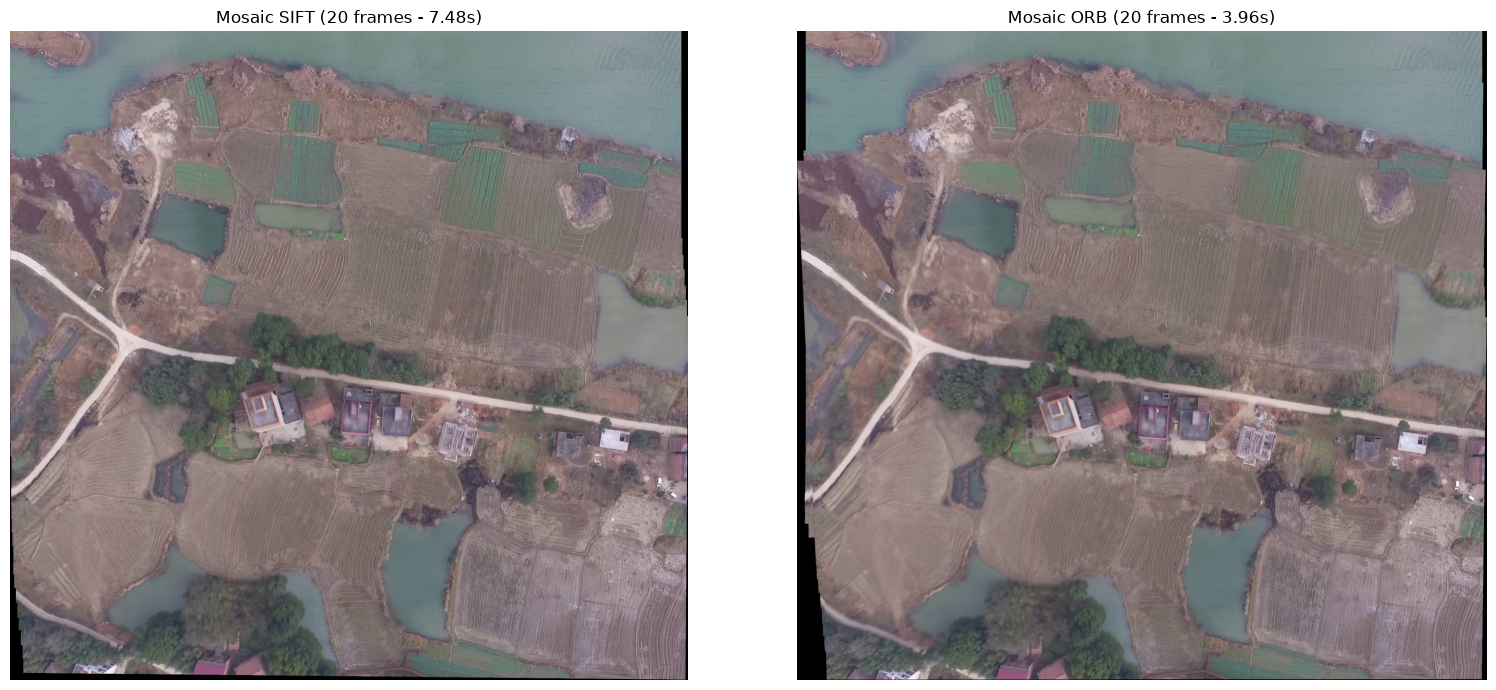

In [7]:
NUM_TEST_FRAMES = 20
METHODS = ["SIFT", "ORB"]
selected_files = img_files[:NUM_TEST_FRAMES]

experiment_results = {}

print(f"=== BẮT ĐẦU THỰC NGHIỆM TRÊN {len(selected_files)} FRAMES ===\n")
for method in METHODS:
    cv2.setRNGSeed(0)
    t_start = time.perf_counter()
    mosaic_img, H_mosaics, metrics = run_mosaic_pipeline(selected_files, method=method, num_frames=len(selected_files))
    total_sec = time.perf_counter() - t_start
    
    # Lưu ảnh kết quả
    img_out = OUTPUT_DIR / f"mosaic_{method.lower()}_{len(selected_files)}frames.png"
    if not cv2.imwrite(str(img_out), mosaic_img):
        raise OSError(f"Không lưu được ảnh: {img_out}")
    
    # Lưu metrics log (chứa cả ma trận H_to_mosaic ánh xạ đúng vào ảnh mosaic)
    log_out = OUTPUT_DIR / f"metrics_{method.lower()}_{len(selected_files)}frames.json"
    with open(log_out, "w", encoding="utf-8") as f:
        json.dump({
            "sequence": SEQUENCE_NAME,
            "method": method,
            "num_frames_requested": len(selected_files),
            "pipeline_total_seconds": round(total_sec, 2),
            "H_to_mosaic": H_mosaics,
            "frames": metrics
        }, f, indent=2, allow_nan=False)
    
    experiment_results[method] = {
        "mosaic": mosaic_img,
        "total_sec": total_sec,
        "metrics": metrics,
        "img_file": img_out,
        "log_file": log_out
    }
    print(f"  💾 Lưu ảnh: {img_out.name}")
    print(f"  💾 Lưu log:  {log_out.name}")
    print("")

# Bảng tổng hợp so sánh trực tiếp
header = f"{'THUẬT TOÁN':<12} | {'TỔNG THỜI GIAN':<16} | {'INLIERS TB':<12} | {'INLIER RATIO':<14} | {'RMSE TB':<10}"
print("=" * len(header))
print(header)
print("-" * len(header))
for method in METHODS:
    res = experiment_results[method]
    valid = [m for m in res["metrics"] if m.get("status") == "success"]
    avg_inliers = float(np.mean([m["inliers"] for m in valid])) if valid else 0.0
    avg_ratio = float(np.mean([m["inlier_ratio"] for m in valid]) * 100) if valid else 0.0
    avg_rmse = float(np.mean([m["rmse"] for m in valid])) if valid else 0.0
    sec_str = f"{res['total_sec']:.2f} s"
    ratio_str = f"{avg_ratio:.1f} %"
    rmse_str = f"{avg_rmse:.2f} px"
    print(f"{method:<12} | {sec_str:<16} | {avg_inliers:<12.1f} | {ratio_str:<14} | {rmse_str:<10}")
print("=" * len(header))

# Hiển thị trực quan cả 2 bức ảnh ghép cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for idx, method in enumerate(METHODS):
    axes[idx].imshow(cv2.cvtColor(experiment_results[method]["mosaic"], cv2.COLOR_BGR2RGB))
    axes[idx].set_title(f"Mosaic {method} ({len(selected_files)} frames - {experiment_results[method]['total_sec']:.2f}s)")
    axes[idx].axis("off")
plt.tight_layout()
plt.show()
